In [1]:
from itertools import islice
import os
from tqdm import tqdm

import numpy as np
import cupy as cp
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.gridspec import GridSpec
from matplotlib.widgets import Slider
from matplotlib.ticker import ScalarFormatter

from scipy.signal import butter, filtfilt, freqz
from scipy.signal import find_peaks
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter
from scipy.optimize import differential_evolution

In [2]:
from IPython import get_ipython

def set_widget_backend():
    plt.close('all')
    get_ipython().run_line_magic('matplotlib', 'widget')

def set_inline_backend():
    plt.close('all')
    get_ipython().run_line_magic('matplotlib', 'inline')

In [3]:
ROOT_DIR = "C:/Dev/Data/University/VKR/Датасеты_мемристоров_ННГУ/Временные ряды для ЛЭТИ 2023_06_07"

PATH_TO_IN = os.path.join(ROOT_DIR, "Input Voltage Pila -1.1_1.5V_full.txt")
PATH_TO_OUT = os.path.join(ROOT_DIR, "Output Voltage Pila-1.1+1.5V_1e6_1e6_1kOhm_1.txt")

In [4]:
dt = 1e-6   # time step 
R = 1000    # resistance

In [5]:
# Чтение данных

# ==============================================================================

def read_data(file_path: str, max_rows: int | None = None) -> np.ndarray:
    return pd.read_csv(
        file_path, header=None, sep='|', decimal=',',
        nrows=max_rows, engine='c', usecols=[0]
    ).to_numpy(dtype=np.float64).ravel()

# ==============================================================================
def count_rows(file_path: str) -> int:
    if os.path.getsize(file_path) == 0:
        return 0
    
    n = 0
    with open(file_path, 'rb') as f:
        while chunk := f.read(1 << 20):
            n += chunk.count(b'\n')

    return n + (chunk[-1:] != b'\n')

# ==============================================================================

def read_data_writable(path: str, max_rows: int | None = None, n_chunk_rows: int = 10000) -> np.ndarray:
    if max_rows is None:
        max_rows = count_rows(path)
    arr = np.empty(max_rows, dtype=np.float64)

    idx = 0
    for df in pd.read_csv(path, chunksize=n_chunk_rows, nrows=max_rows, header=None, decimal=',', engine='c', usecols=[0]):
        chunk = df.iloc[:, 0].to_numpy()
        arr[idx:idx+len(chunk)] = chunk
        idx += len(chunk)
    
    return arr

In [6]:
# Форматирование меток на графиках

# отображение графиков в мА / мС / кОм без аллокации нового массива
formatter_to_mA  = FuncFormatter(lambda y, _: f'{y*1000:.1f}')
formatter_to_mS  = FuncFormatter(lambda y, _: int(y*1000))
formatter_to_mV  = FuncFormatter(lambda y, _: f'{y*1000:.3f}')
formatter_to_mSm = FuncFormatter(lambda y, _: f'{y*1000:.3f}')
formatter_to_kOm = FuncFormatter(lambda y, _: f'{y/1000:.3f}')

# Форматирование меток на оси Y в научной нотации
def set_scientific_yaxis(ax, scilimits=(0, 1)):
    fmt = ScalarFormatter(useMathText=True)
    fmt.set_powerlimits(scilimits)
    ax.yaxis.set_major_formatter(fmt)

def set_scientific_xaxis(ax, scilimits=(0, 1)):
    fmt = ScalarFormatter(useMathText=True)
    fmt.set_powerlimits(scilimits)
    ax.xaxis.set_major_formatter(fmt)

In [7]:
def calculate_R(V, I):
    R = np.empty_like(V)
    np.divide(V, I, out=R, where=(I != 0))
    R[I == 0] = np.inf
    return R

def calculate_G(V, I):
    G = np.empty_like(V)
    np.divide(I, V, out=G, where=(V != 0))
    G[V == 0] = np.inf
    return G

def build_time_array(start, end, dt, endpoint=True):
    n = int(np.round((end - start) / dt)) + (1 if endpoint else 0)
    return np.linspace(start, end, n, endpoint=endpoint)

In [17]:
def detect_breakpoint(
    y: np.ndarray,
    min_seg_len: int = 5,
    weights=(0.5, 0.5),
    x: np.ndarray = None
):
    # Кусочно-линейная аппроксимация с оптимизацией точки излома.
    # Минимизирует RSS двух прямых.
    
    n_points = len(y)
    
    valid_range = range(min_seg_len, n_points - min_seg_len + 1)
    best_k, best_rss = None, np.inf
    
    for k in valid_range:
        y1 = y[:k]
        y2 = y[k:]
        
        # Линейная аппроксимация по индексу (равномерная дискретизация)
        x1 = x[:k] if (x is not None) else np.arange(len(y1))
        x2 = x[k:] if (x is not None) else np.arange(len(y2))
        m1, c1 = np.polyfit(x1, y1, 1)
        m2, c2 = np.polyfit(x2, y2, 1)
        
        rss1 = np.sum((y1 - (m1*x1 + c1))**2)
        rss2 = np.sum((y2 - (m2*x2 + c2))**2)

        rss = weights[0] * rss1 + weights[1] * rss2

        # rss = np.sum((y1 - (m1*x1 + c1))**2) + np.sum((y2 - (m2*x2 + c2))**2)
        # rss = np.sum(np.abs(y1 - (m1*x1 + c1))) + np.sum(np.abs(y2 - (m2*x2 + c2)))
        
        if rss < best_rss:
            best_rss = rss
            best_k = k
    
    return best_k, best_rss

# Чтение данных

In [8]:
# считаем ~10 циклов ВАХ-ки
max_rows = 5200 * (10 + 1)

arr_v = read_data(PATH_TO_IN, max_rows=max_rows)
arr_i = read_data_writable(PATH_TO_OUT, max_rows=max_rows, n_chunk_rows=100_000)
arr_i /= R

print(f"Input length: {len(arr_v)}")
print(f"Output length: {len(arr_i)}")

Input length: 57200
Output length: 57200


In [9]:
N = len(arr_v)

arr_g = np.empty_like(arr_v)
np.divide(arr_i, arr_v, out=arr_g, where=(arr_v != 0))
arr_g[arr_v == 0] = np.inf

arr_t = np.linspace(0, (N - 1) * dt, N)
print(f"Time range (seconds): [0; {arr_t[-1]}]")

Time range (seconds): [0; 0.057199]


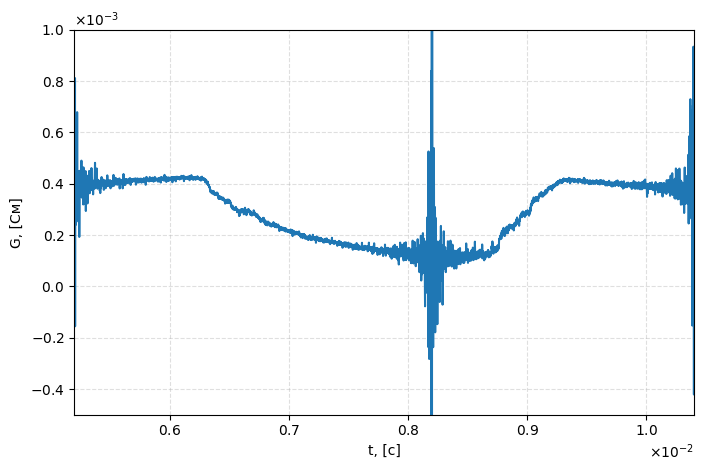

In [44]:
set_inline_backend()

start = 5200; end = 10400 + 1

T = build_time_array(start*dt, end*dt, dt, endpoint=False)
V = arr_v[start : end]
I = arr_i[start : end]

G = calculate_G(V, I)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(T, G)
ax.set_xlim(T[0], T[-1])
ax.set_ylim(-0.5e-3, 1e-3)
ax.grid(True, linestyle='--', alpha=0.4)
ax.set(xlabel='t, [c]', ylabel='G, [См]')
set_scientific_yaxis(ax)
set_scientific_xaxis(ax)

plt.show()

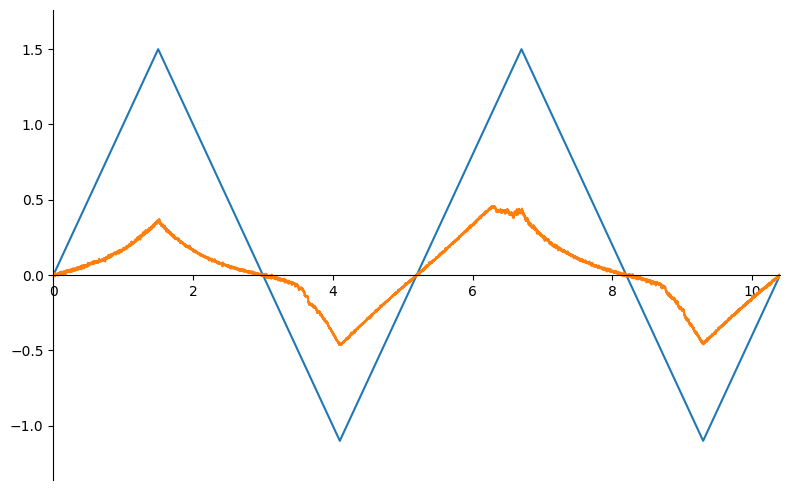

In [10]:
start = 0; end = 10400 + 1

T = build_time_array(start*dt, end*dt, dt, endpoint=False)
V = arr_v[start : end]
I = arr_i[start : end]
Vout = I * R

T *= 1000

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(T, V)
ax.plot(T, Vout)
# ax.grid(True, linestyle='--', alpha=0.5)

# Сначала задаем лимиты, потом позиционируем оси
ax.set_xlim(T.min(), T.max())
y_min, y_max = min(V.min(), Vout.min()), max(V.max(), Vout.max())
ax.set_ylim(y_min - 0.1*(y_max-y_min), y_max + 0.1*(y_max-y_min))

# Убираем верхнюю и правую границы
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# Перемещаем нижнюю и левую оси в начало координат (если 0 в диапазоне)
if ax.get_ylim()[0] <= 0 <= ax.get_ylim()[1]:
    ax.spines['bottom'].set_position('zero')
if ax.get_xlim()[0] <= 0 <= ax.get_xlim()[1]:
    ax.spines['left'].set_position('zero')

# Сдвигаем подписи осей в начало координат
ax.xaxis.set_label_coords(1.02, -0.02)
ax.yaxis.set_label_coords(-0.03, 1.02)

plt.tight_layout()
plt.show()

break detected on t = 0.705411


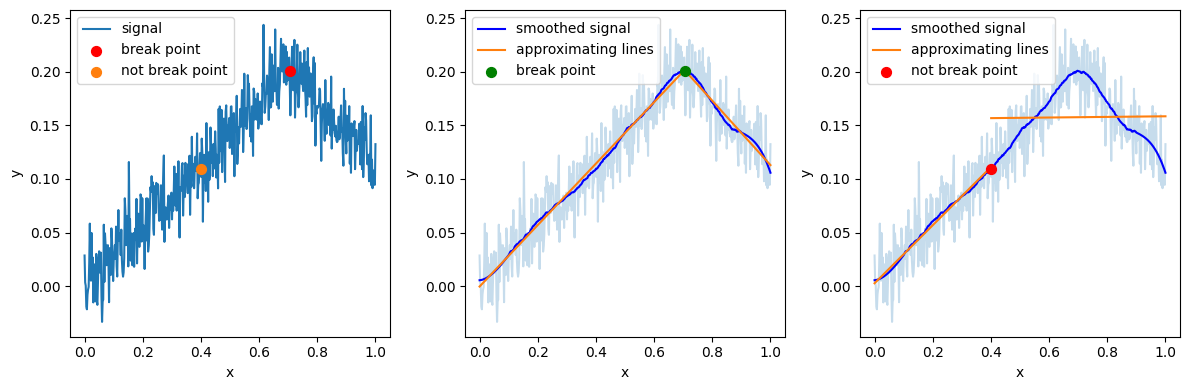

In [34]:
# ==============================================================================
# TEST CODE
# ==============================================================================
set_inline_backend()

t = np.linspace(0, 1, 500)
# clean = np.where(t < 0.4, 0.5*t, 0.2 + 0.1*(t-0.4))  # Излом в t=0.4
clean = np.where(t < 0.7, 0.2/0.7*t, 0.2 + -0.3*(t-0.7))  # Излом в t=0.7
noisy = clean + np.random.normal(0, 0.02, size=t.shape)

smoothed = savgol_filter(noisy, window_length=101, polyorder=3)

min_seg_len = 10
index, _ = detect_breakpoint(smoothed, min_seg_len)
index2 = 200

if index != -1:
    print(f"break detected on t = {t[index]:.6f}")

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].plot(t, noisy, zorder=0, label='signal')
    axes[0].scatter(t[index], smoothed[index], s=50, c='red', zorder=1, label='break point')
    axes[0].scatter(t[index2], smoothed[index2], s=50, c='C1', zorder=1, label='not break point')

    y1 = smoothed[:index]
    y2 = smoothed[index:]
    x1, x2 = np.arange(len(y1)), np.arange(len(y2))
    m1, c1 = np.polyfit(x1, y1, 1)
    m2, c2 = np.polyfit(x2, y2, 1)

    axes[1].plot(t, noisy, alpha=0.25, zorder=0)
    axes[1].plot(t, smoothed, color='blue', zorder=0, label='smoothed signal')
    axes[1].plot(t[:index], m1*x1 + c1, alpha=1, color='C1', zorder=1, label='approximating lines')
    axes[1].plot(t[index:], m2*x2 + c2, alpha=1, color='C1', zorder=1)
    axes[1].scatter(t[index], smoothed[index], s=50, c='green', zorder=1, label='break point')

    y1 = smoothed[:index2]
    y2 = smoothed[index2:]
    x1, x2 = np.arange(len(y1)), np.arange(len(y2))
    m1, c1 = np.polyfit(x1, y1, 1)
    m2, c2 = np.polyfit(x2, y2, 1)

    axes[2].plot(t, noisy, alpha=0.25, zorder=0)
    axes[2].plot(t, smoothed, color='blue', zorder=0, label='smoothed signal')
    axes[2].plot(t[:index2], m1*x1 + c1, alpha=1, color='C1', zorder=1, label='approximating lines')
    axes[2].plot(t[index2:], m2*x2 + c2, alpha=1, color='C1', zorder=1)
    axes[2].scatter(t[index2], smoothed[index2], s=50, c='red', zorder=1, label='not break point')

    for ax in axes:
        ax.set(xlabel='x', ylabel='y')
        ax.legend(loc='upper left')
    
    rss = np.sum((y1 - (m1*x1 + c1))**2) + np.sum((y2 - (m2*x2 + c2))**2)

    plt.tight_layout()
    plt.show()
else:
    print(f"Empty search interval")

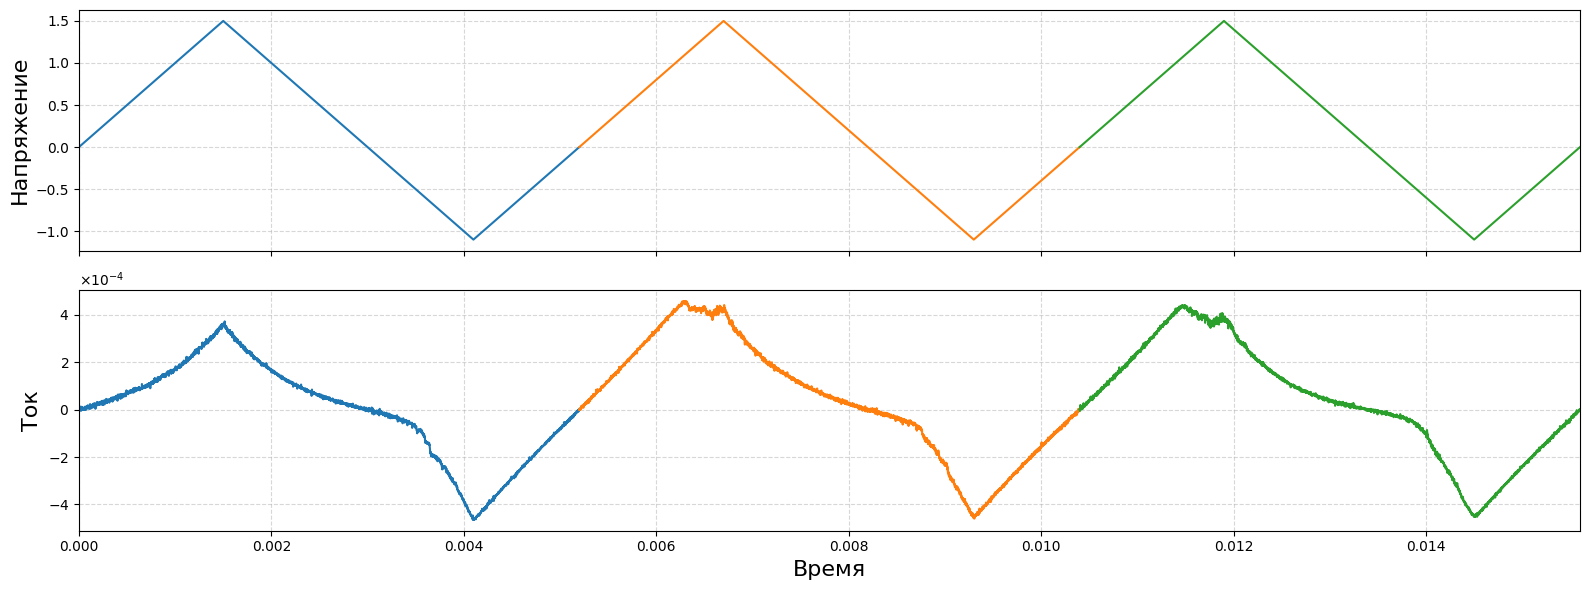

In [29]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 6), sharex=True)

zero_indices = np.where(arr_v == 0)[0]
n_cycles = 3

for i in range(n_cycles):
    start, end = zero_indices[i * 2], zero_indices[(i + 1) * 2] + 1

    ax1.plot(arr_t[start : end], arr_v[start : end])
    ax2.plot(arr_t[start : end], arr_i[start : end])

ax1.set_ylabel("Напряжение", fontsize=16)
ax2.set_ylabel("Ток", fontsize=16)
ax2.set_xlabel("Время", fontsize=16)

set_scientific_yaxis(ax2)

for ax in [ax1, ax2]:
    ax.set_xlim(arr_t[zero_indices[0]], arr_t[zero_indices[n_cycles * 2]])
    ax.grid(True, linestyle='--', alpha=0.5)

# fig.suptitle('1 цикл', x=0.54, y=0.97)
# fig.supxlabel('t, [мС]', x=0.54, y=0.05)
# fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()

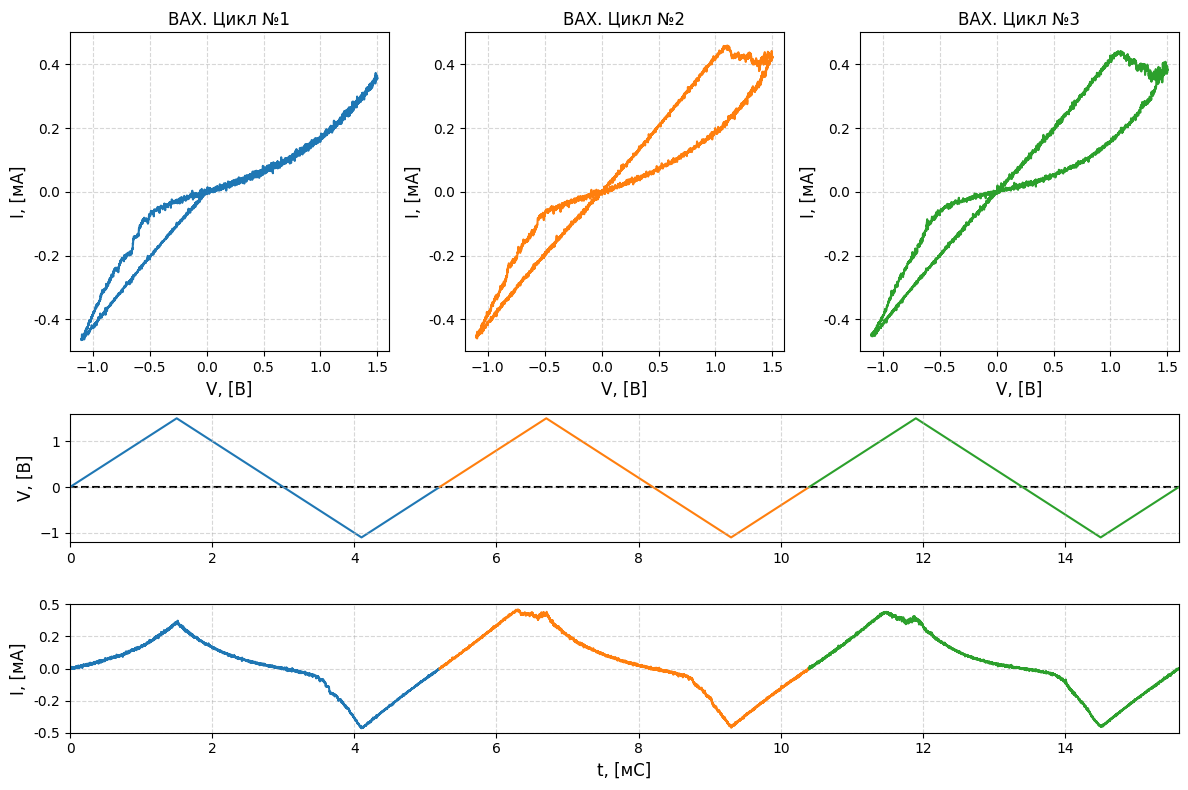

In [11]:
fig = plt.figure(figsize=(12, 8))
zero_indices = np.where(arr_v == 0)[0]
n_cycles = 3

ax_v = plt.subplot2grid((4, n_cycles), (2, 0), colspan=n_cycles)
ax_i = plt.subplot2grid((4, n_cycles), (3, 0), colspan=n_cycles, sharex=ax_v)

axes_vah = []
for i in range(n_cycles):
    ax_vah = plt.subplot2grid((4, n_cycles), (0, i), rowspan=2)

    start, end = zero_indices[i * 2], zero_indices[(i + 1) * 2] + 1

    ax_v.plot(arr_t[start : end], arr_v[start : end], zorder=1)
    ax_i.plot(arr_t[start : end], arr_i[start : end])
    ax_vah.plot(arr_v[start : end], arr_i[start : end], color=f"C{i}")

    ax_vah.set_title(f"ВАХ. Цикл №{i + 1}", fontsize=12)

    axes_vah += [ax_vah]

ax_v.set_ylabel("V, [В]", fontsize=12)
ax_i.set_ylabel("I, [мА]", fontsize=12)
ax_i.set_xlabel("t, [мС]", fontsize=12)

ax_i.xaxis.set_major_formatter(formatter_to_mS)
ax_v.set_ylim(-1.2, 1.6)

ax_v.axhline(0, color='black', linestyle='--', zorder=0)

for ax in [ax_v, ax_i]:
    ax.set_xlim(arr_t[zero_indices[0]], arr_t[zero_indices[n_cycles * 2]])

for ax in axes_vah + [ax_v, ax_i]:
    ax.grid(True, linestyle='--', alpha=0.5)

for ax in axes_vah + [ax_i]:
    ax.yaxis.set_major_formatter(formatter_to_mA)
    ax.set_ylim(-0.5e-3, 0.5e-3)

for ax in axes_vah:
    ax.set_xlabel("V, [В]", fontsize=12)
    ax.set_ylabel("I, [мА]", fontsize=12)
    ax.set_xlim(-1.2, 1.6)

# fig.suptitle('1 цикл', x=0.54, y=0.97)
# fig.supxlabel('t, [мС]', x=0.54, y=0.05)
# fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()

# ывфаыфа

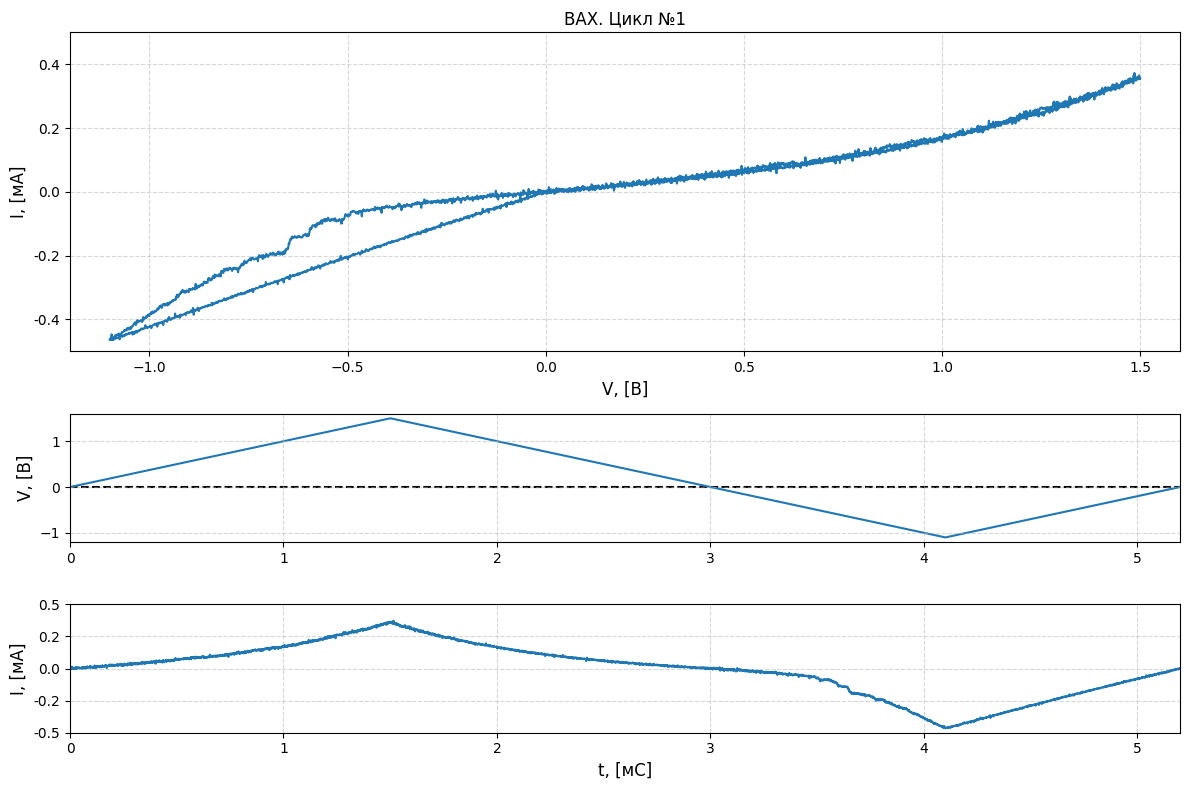

In [12]:
fig = plt.figure(figsize=(12, 8))
zero_indices = np.where(arr_v == 0)[0]
n_cycles = 1

ax_v = plt.subplot2grid((4, n_cycles), (2, 0), colspan=n_cycles)
ax_i = plt.subplot2grid((4, n_cycles), (3, 0), colspan=n_cycles, sharex=ax_v)

axes_vah = []
for i in range(n_cycles):
    ax_vah = plt.subplot2grid((4, n_cycles), (0, i), rowspan=2)

    start, end = zero_indices[i * 2], zero_indices[(i + 1) * 2] + 1

    ax_v.plot(arr_t[start : end], arr_v[start : end], zorder=1)
    ax_i.plot(arr_t[start : end], arr_i[start : end])
    ax_vah.plot(arr_v[start : end], arr_i[start : end], color=f"C{i}")

    ax_vah.set_title(f"ВАХ. Цикл №{i + 1}", fontsize=12)

    axes_vah += [ax_vah]

ax_v.set_ylabel("V, [В]", fontsize=12)
ax_i.set_ylabel("I, [мА]", fontsize=12)
ax_i.set_xlabel("t, [мС]", fontsize=12)

ax_i.xaxis.set_major_formatter(formatter_to_mS)
ax_v.set_ylim(-1.2, 1.6)

ax_v.axhline(0, color='black', linestyle='--', zorder=0)

for ax in [ax_v, ax_i]:
    ax.set_xlim(arr_t[zero_indices[0]], arr_t[zero_indices[n_cycles * 2]])

for ax in axes_vah + [ax_v, ax_i]:
    ax.grid(True, linestyle='--', alpha=0.5)

for ax in axes_vah + [ax_i]:
    ax.yaxis.set_major_formatter(formatter_to_mA)
    ax.set_ylim(-0.5e-3, 0.5e-3)

for ax in axes_vah:
    ax.set_xlabel("V, [В]", fontsize=12)
    ax.set_ylabel("I, [мА]", fontsize=12)
    ax.set_xlim(-1.2, 1.6)

# fig.suptitle('1 цикл', x=0.54, y=0.97)
# fig.supxlabel('t, [мС]', x=0.54, y=0.05)
# fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()